# 03 - Features, Split, Models, Intervals and Export

**Input:** `data/processed/shipments.csv` (from `01_data_preparation.ipynb`), `src/features.py`, `src/predict.py`
**Output:** `models/transit_model.joblib`, the file loaded by the Streamlit app

Steps: chronological split, model comparison, small tuning run, final fit, **90% and 80% prediction intervals**
(quantile regression plus conformal calibration), coverage checks, explainability and export.

All errors are reported in **days**. Models are trained on `log1p(transit_days)` because the target is strongly skewed (see EDA).

## 0. Setup

In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q shap lightgbm

In [2]:
import json
import warnings
from datetime import datetime, timezone

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", message="X does not have valid feature names")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED = 42

def ensure(dest, label):
    """Make sure `dest` exists. In Colab, ask for an upload when it is missing."""
    dest = Path(dest)
    if dest.exists():
        return dest
    if IN_COLAB:
        from google.colab import files

        print(f"Please upload: {label}")
        dest.parent.mkdir(parents=True, exist_ok=True)
        for name, content in files.upload().items():
            (dest.parent / name).write_bytes(content)
    assert dest.exists(), f"{dest} not found. Run the earlier step first or upload {label}."
    return dest

ensure(ROOT / "src" / "features.py", "src/features.py")
ensure(ROOT / "src" / "predict.py", "src/predict.py")
data_path = ensure(ROOT / "data" / "processed" / "shipments.csv", "shipments.csv")

sys.path.insert(0, str(ROOT / "src"))
from features import FEATURES, TARGET, add_features
import predict

## 1. Load and split chronologically

EDA showed the target drifts over time, so a random split would be too optimistic.
The data is sorted by dispatch date and cut into four consecutive blocks:

| Block | Share | Use |
|---|---|---|
| train | 60% | fit candidate models |
| validation | 15% | compare models, tune, choose features |
| calibration | 10% | conformal calibration of the intervals only |
| test | 15% (most recent) | touched once, for the final report |

In [3]:
df = (pd.read_csv(data_path, parse_dates=["dispatch_date"])
        .sort_values(["dispatch_date", "order_id"]).reset_index(drop=True))
n = len(df)
i1, i2, i3 = int(n * .60), int(n * .75), int(n * .85)
train, val, cal, test = df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:i3], df.iloc[i3:]

summary = pd.DataFrame({
    "rows": [len(x) for x in (train, val, cal, test)],
    "from": [x["dispatch_date"].min().date() for x in (train, val, cal, test)],
    "to": [x["dispatch_date"].max().date() for x in (train, val, cal, test)],
    "mean_days": [x[TARGET].mean().round(2) for x in (train, val, cal, test)],
    "median_days": [x[TARGET].median().round(2) for x in (train, val, cal, test)],
}, index=["train", "validation", "calibration", "test"])
summary

,rows,from,to,mean_days,median_days
train,56679,2016-10-08,2018-03-06,9.93,7.93
validation,14170,2018-03-06,2018-05-08,10.31,7.43
calibration,9447,2018-05-08,2018-06-22,8.12,6.33
test,14170,2018-06-22,2018-09-11,5.64,5.15


The blocks differ noticeably (mean transit time 9.9 days in train, 10.3 in validation, 8.1 in calibration and 5.6 in test).
The test period is **faster** than anything the models are trained on, so absolute test errors will look better than validation errors.
Both are reported, and neither should be read as a guarantee for a different period.

## 2. Features

Built by `src/features.py`: `log_weight`, `log_distance`, `warehouse_load`, `tier_ord` (Economy 0, Standard 1, Express 2) and `dispatch_dow`.
The same function is used by the Streamlit app, so training and serving cannot diverge.

In [4]:
Xtr, Xva, Xca, Xte = (add_features(x) for x in (train, val, cal, test))
ytr, yva, yca, yte = (np.log1p(x[TARGET]) for x in (train, val, cal, test))
Xtr.describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
log_weight,56679.0,0.84,0.75,0.05,0.26,0.59,1.13,5.22
log_distance,56679.0,5.84,1.33,0.00,5.43,6.12,6.70,8.13
warehouse_load,56679.0,3.66,4.56,1.00,1.00,2.00,4.00,62.00
tier_ord,56679.0,0.94,0.81,0.00,0.00,1.00,2.00,2.00
dispatch_dow,56679.0,1.99,1.45,0.00,1.00,2.00,3.00,6.00


## 3. Metrics helper and baselines

`MAE` (mean absolute error, in days) is the headline metric because it reads directly as "typically off by X days".
The reference baseline is predicting the training median for every shipment.

In [5]:
def report(y_days, pred_days):
    return {
        "MAE": mean_absolute_error(y_days, pred_days),
        "RMSE": float(np.sqrt(mean_squared_error(y_days, pred_days))),
        "R2": r2_score(y_days, pred_days),
    }


rows = {}
const = np.full(len(val), train[TARGET].median())
rows["baseline: training median"] = {
    **{f"val_{k}": v for k, v in report(val[TARGET], const).items()},
}
pd.DataFrame(rows).T.round(3)

,val_MAE,val_RMSE,val_R2
baseline: training median,6.335,9.472,-0.068


## 4. Model comparison (train on train, score on validation)

All models predict `log1p(days)`; predictions are converted back to days before scoring.
Gradient boosting with an L1 objective (LightGBM) is included because it is the model family used for the intervals later.

In [6]:
LGB_BASE = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)

candidates = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=SEED),
    "Gradient Boosting (sklearn)": GradientBoostingRegressor(loss="absolute_error", n_estimators=200, max_depth=4, random_state=SEED),
    "LightGBM (L1)": lgb.LGBMRegressor(objective="l1", **LGB_BASE),
}

results = dict(rows)
for name, model in candidates.items():
    model.fit(Xtr, ytr)
    results[name] = {f"val_{k}": v for k, v in report(val[TARGET], np.expm1(model.predict(Xva))).items()}

comparison = pd.DataFrame(results).T.sort_values("val_MAE")
comparison.round(3)

,val_MAE,val_RMSE,val_R2
LightGBM (L1),4.857,8.096,0.220
Gradient Boosting (sklearn),4.876,8.126,0.214
Random Forest,4.908,8.008,0.237
Ridge,4.977,8.098,0.220
baseline: training median,6.335,9.472,-0.068


In [7]:
base_mae = comparison.loc["baseline: training median", "val_MAE"]
best_name = comparison.drop(index="baseline: training median")["val_MAE"].idxmin()
lgb_mae = comparison.loc["LightGBM (L1)", "val_MAE"]
print(f"best model by validation MAE : {best_name} ({comparison.loc[best_name, 'val_MAE']:.3f} days)")
print(f"LightGBM (L1)                : {lgb_mae:.3f} days")
print(f"baseline (median)            : {base_mae:.3f} days")
print(f"LightGBM improvement over baseline: {(1 - lgb_mae / base_mae) * 100:.1f}%")

best model by validation MAE : LightGBM (L1) (4.857 days)
LightGBM (L1)                : 4.857 days
baseline (median)            : 6.335 days
LightGBM improvement over baseline: 23.3%


**Reading the comparison:** all four models land within about 0.12 days of each other (4.86 to 4.98 days). A straight Ridge regression is almost as good as boosting,
because the relationship is dominated by one feature, distance. Boosting is kept because it is also the family used for the interval models.
The gain over the naive baseline (about 23%) is real, but the absolute fit is modest: R2 is only about 0.22 on validation.

## 5. Which features matter? (ablation on validation)

Each row refits LightGBM with one feature removed. If removing a feature does not hurt, it adds nothing the others do not already provide.
The last row adds `dispatch_month`, which is **not** in the feature set, to show why it was left out.

In [8]:
def fit_val_mae(cols, extra_tr=None, extra_va=None):
    a, b = Xtr[cols].copy(), Xva[cols].copy()
    if extra_tr is not None:
        a["dispatch_month"], b["dispatch_month"] = extra_tr, extra_va
    m = lgb.LGBMRegressor(objective="l1", **LGB_BASE).fit(a, ytr)
    return mean_absolute_error(val[TARGET], np.expm1(m.predict(b)))


abl = {"all features": fit_val_mae(FEATURES)}
for f in FEATURES:
    abl[f"without {f}"] = fit_val_mae([c for c in FEATURES if c != f])
abl["with dispatch_month added"] = fit_val_mae(
    FEATURES, train["dispatch_date"].dt.month.values, val["dispatch_date"].dt.month.values)

ablation = pd.Series(abl, name="val_MAE").round(3).to_frame()
ablation["change_vs_all"] = (ablation["val_MAE"] - ablation.loc["all features", "val_MAE"]).round(3)
ablation

,val_MAE,change_vs_all
all features,4.857,0.000
without log_weight,4.869,0.012
without log_distance,5.684,0.827
without warehouse_load,4.870,0.013
without tier_ord,4.862,0.005
without dispatch_dow,4.905,0.048
with dispatch_month added,4.993,0.136


Reading the table: removing `log_distance` is by far the most damaging change. The other features change validation MAE very little.
Adding `dispatch_month` does **not** help on validation, and the data covers under two years, so a month feature would only memorise
the specific months seen once or twice. It stays out.

## 6. Small tuning run (LightGBM, validation set)

A few settings are compared on the validation block only. The test block is not used for any choice.

In [9]:
grid = [dict(num_leaves=nl, min_child_samples=mc, learning_rate=lr, n_estimators=ne)
        for nl in (15, 31, 63) for mc in (50, 200) for lr, ne in ((0.05, 400), (0.03, 300))]

tuning = []
for g in grid:
    params = {**LGB_BASE, **g}
    m = lgb.LGBMRegressor(objective="l1", **params).fit(Xtr, ytr)
    tuning.append({**g, "val_MAE": mean_absolute_error(val[TARGET], np.expm1(m.predict(Xva)))})

tuning = pd.DataFrame(tuning).sort_values("val_MAE").reset_index(drop=True)
display(tuning.head(5).round(3))
best_params = {**LGB_BASE, **tuning.iloc[0].drop("val_MAE").to_dict()}
for k in ("num_leaves", "min_child_samples", "n_estimators"):
    best_params[k] = int(best_params[k])
print("chosen:", {k: best_params[k] for k in ("num_leaves", "min_child_samples", "learning_rate", "n_estimators")})
print(f"spread between best and worst setting: {tuning['val_MAE'].max() - tuning['val_MAE'].min():.3f} days")

,num_leaves,min_child_samples,learning_rate,n_estimators,val_MAE
0,15,50,0.05,400,4.854
1,31,50,0.05,400,4.857
2,31,200,0.05,400,4.858
3,15,200,0.05,400,4.858
4,63,50,0.03,300,4.858


chosen: {'num_leaves': 15, 'min_child_samples': 50, 'learning_rate': 0.05, 'n_estimators': 400}
spread between best and worst setting: 0.017 days


## 7. Final fit and prediction intervals

**Final models** are fitted on train + validation, so they see the most recent data. They are then calibrated on the calibration block and scored once on the test block.

**Intervals** use quantile regression (LightGBM with a quantile objective) for the lower and upper bounds, then a conformal correction
(*conformalized quantile regression*): on the calibration block we measure how far true values fall outside the raw bounds, and widen the interval by that amount.
The correction is **only allowed to widen** the interval, never to shrink it.

> **Honest note on this choice.** The first run allowed negative corrections. The calibration block is an easier period than the data the models were fitted on,
> so the correction came out negative, the intervals shrank, and test coverage fell to about 86% for a 90% interval.
> "Only widen" was adopted **after** seeing that test result, so the coverage numbers below are no longer a completely untouched estimate.
> With this rule the correction on this data is exactly 0 (see the cell below), so **in practice the intervals are the raw quantile-regression intervals**.
> The conformal step is kept in the pipeline as a safety net that triggers if a future calibration block is harder than the training data.

Two levels are produced, 80% and 90%.

In [10]:
fit = pd.concat([train, val])
Xfit, yfit = add_features(fit), np.log1p(fit[TARGET])

models = {"median": lgb.LGBMRegressor(objective="l1", **best_params).fit(Xfit, yfit)}
for a in (0.05, 0.1, 0.9, 0.95):
    models[f"q{a:g}"] = lgb.LGBMRegressor(objective="quantile", alpha=a, **best_params).fit(Xfit, yfit)


def conformal_shift(level, lo_key, hi_key):
    lo, hi = models[lo_key].predict(Xca), models[hi_key].predict(Xca)
    lo, hi = np.minimum(lo, models["median"].predict(Xca)), np.maximum(hi, models["median"].predict(Xca))
    score = np.maximum(lo - yca, yca - hi)                      # >0 when the truth falls outside the raw bounds
    k = min(1.0, np.ceil((len(score) + 1) * level) / len(score))
    return max(0.0, float(np.quantile(score, k, method="higher")))   # only ever widen, never shrink the raw interval


conformal = {"0.9": conformal_shift(0.9, "q0.05", "q0.95"), "0.8": conformal_shift(0.8, "q0.1", "q0.9")}
print("conformal widening (log1p units, 0 means the raw quantile interval was already wide enough on calibration data):",
      {k: round(v, 3) for k, v in conformal.items()})

conformal widening (log1p units, 0 means the raw quantile interval was already wide enough on calibration data): {'0.9': 0.0, '0.8': 0.0}


### Bundle

Everything the app needs goes into one dictionary, so the Streamlit app has no modelling code.

In [11]:
fit_ranges = {c: [float(fit[c].min()), float(fit[c].max())] for c in ("weight_kg", "distance_km", "warehouse_load")}

bundle = {
    "models": models,
    "conformal": conformal,
    "features": FEATURES,
    "ranges": fit_ranges,
    "target": TARGET,
    "levels": [0.8, 0.9],
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "fit_period": [str(fit["dispatch_date"].min().date()), str(fit["dispatch_date"].max().date())],
    "versions": {"lightgbm": lgb.__version__, "scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
    "params": {k: v for k, v in best_params.items() if k != "verbose"},
}

## 8. Test-set evaluation

Scored through `predict.predict_frame`, exactly the code path the app uses.

In [12]:
point = predict.predict_frame(bundle, test, level=0.9)
test_metrics = report(test[TARGET], point["estimate_days"])
base_test = report(test[TARGET], np.full(len(test), fit[TARGET].median()))

final = pd.DataFrame({"final model": test_metrics, "baseline (training median)": base_test}).T
display(final.round(3))
print(f"MAE improvement over the baseline: {(1 - test_metrics['MAE'] / base_test['MAE']) * 100:.1f}%")

# same model scored on the validation block as a more demanding (slower, drifting) period
val_point = predict.predict_frame(bundle, val, level=0.9)
print("validation MAE of the final models (they were fitted on this block, so this is optimistic):",
      round(mean_absolute_error(val[TARGET], val_point["estimate_days"]), 3))

,MAE,RMSE,R2
final model,3.031,4.166,0.041
baseline (training median),3.775,4.811,-0.278


MAE improvement over the baseline: 19.7%


validation MAE of the final models (they were fitted on this block, so this is optimistic): 4.751


The earlier model comparison scored models on the validation block **before** it was used for fitting, which is the fair comparison (MAE about 4.9 days against about 6.3 for the baseline).
The test block is a faster period, so its absolute MAE is lower.

## 9. Interval coverage on the test set

In [13]:
def coverage_table(level):
    p = predict.predict_frame(bundle, test, level)
    inside = (test[TARGET] >= p["lower_days"]) & (test[TARGET] <= p["upper_days"])
    return p, inside


rows = []
for level in (0.8, 0.9):
    p, inside = coverage_table(level)
    # coverage of the raw quantile models, before the conformal widening
    saved = bundle["conformal"][str(level)]
    bundle["conformal"][str(level)] = 0.0
    raw, raw_inside = coverage_table(level)
    bundle["conformal"][str(level)] = saved
    rows.append({
        "nominal": level,
        "coverage before conformal": raw_inside.mean(),
        "coverage after conformal": inside.mean(),
        "mean width (days)": (p["upper_days"] - p["lower_days"]).mean(),
        "median width (days)": (p["upper_days"] - p["lower_days"]).median(),
    })
pd.DataFrame(rows).round(3)

,nominal,coverage before conformal,coverage after conformal,mean width (days),median width (days)
0,0.8,0.771,0.771,12.697,13.278
1,0.9,0.898,0.898,18.207,19.479


In [14]:
p90, inside90 = coverage_table(0.9)
seg = test.assign(inside=inside90.values, width=(p90["upper_days"] - p90["lower_days"]).values)
seg["distance_band"] = pd.cut(seg["distance_km"], [0, 100, 300, 600, 1000, 1500, 4000])

by_band = seg.groupby("distance_band", observed=True).agg(shipments=("inside", "size"), coverage=("inside", "mean"), mean_width_days=("width", "mean"))
by_tier = seg.groupby("carrier_tier").agg(shipments=("inside", "size"), coverage=("inside", "mean"), mean_width_days=("width", "mean"))
display(by_band.round(3))
display(by_tier.round(3))

,shipments,coverage,mean_width_days
distance_band,,,
"(0, 100]",3252,0.967,8.821
"(100, 300]",1962,0.923,15.439
"(300, 600]",4375,0.895,20.276
"(600, 1000]",2443,0.846,21.665
"(1000, 1500]",945,0.851,23.883
"(1500, 4000]",1190,0.822,29.237


,shipments,coverage,mean_width_days
carrier_tier,,,
Economy,3584,0.847,22.880
Express,5754,0.943,13.568
Standard,4832,0.881,20.265


**How to read this**
- Coverage is about the share of real deliveries that land inside the stated range. A 90% range should contain about 90% of them.
- The conformal correction is 0 here, so "before" and "after" are identical. The 90% interval covers about 90% of test shipments, close to its target.
  The **80% interval covers about 77%**, a little below its target, so treat 80% as approximate.
- Intervals are very wide in absolute terms (about 18 days on average for the 90% level, against a mean transit of 5.6 days in the test period).
  Distance explains only part of the variation, and the inputs available here (weight, warehouse load, a proxy tier) say little about individual delays.
  The honest message of the tool is a plausible range, not a precise date.
- Intervals get wider for longer routes, which matches the EDA.
- Coverage is uneven: it is above target for short routes (about 97% under 100 km) and **falls below target for long routes (about 82% beyond 1,500 km) and for the Economy tier (about 85%)**.
  Long, heavy shipments are exactly where the tool is least reliable.

## 10. Delay risk

The app flags delay risk against a **promised delivery time** entered by the dispatcher:

| Label | Meaning |
|---|---|
| High | the estimate itself is later than the promise |
| Medium | the estimate is on time, but the upper bound of the interval is later than the promise |
| Low | even the upper bound is within the promise |

Check that the labels mean something: for a promise of 10 days, the share of test shipments that really took longer should rise from Low to High.

In [15]:
from features import delay_risk

PROMISE_DAYS = 10
risk = delay_risk(p90["estimate_days"].values, p90["upper_days"].values, PROMISE_DAYS)
chk = pd.DataFrame({"risk": risk, "late": (test[TARGET] > PROMISE_DAYS).values})
out = chk.groupby("risk")["late"].agg(shipments="size", share_actually_late="mean").reindex(["Low", "Medium", "High"])
out.round(3)

,shipments,share_actually_late
risk,,
Low,1865,0.011
Medium,8978,0.049
High,3327,0.320


## 11. What drives the estimate (SHAP)

/Users/avinashsoni/anaconda3/envs/xbnb/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


log_distance      0.745
dispatch_dow      0.116
log_weight        0.053
warehouse_load    0.051
tier_ord          0.034
dtype: float64

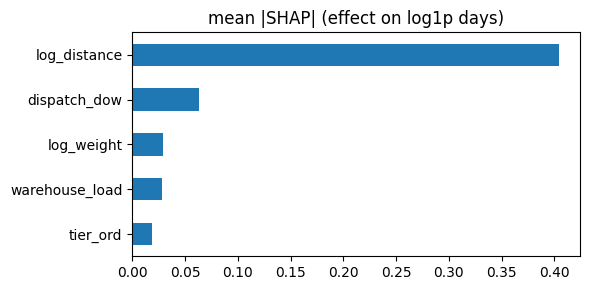

In [16]:
import shap

sample = Xte.sample(2000, random_state=SEED)
explainer = shap.TreeExplainer(models["median"])
sv = explainer.shap_values(sample)
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATURES).sort_values()
imp.plot.barh(title="mean |SHAP| (effect on log1p days)", figsize=(6, 3))
plt.tight_layout()
(imp / imp.sum()).sort_values(ascending=False).round(3)

Distance dominates, as EDA suggested. Weight, warehouse load and the carrier tier proxy add little, and day of week adds some.
That is a property of this dataset (tier is derived from weight and distance, and Olist routes are mostly driven by distance), not a modelling failure.

## 12. Export and verify

The bundle is written with `joblib`, reloaded, and checked to give identical predictions.

In [17]:
bundle["metrics"] = {
    "test": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "baseline_test": {k: round(float(v), 4) for k, v in base_test.items()},
    "validation_mae_comparison": comparison["val_MAE"].round(4).to_dict(),
    "coverage_test": {str(r["nominal"]): round(float(r["coverage after conformal"]), 4) for r in rows},
    "mean_width_days_test": {str(r["nominal"]): round(float(r["mean width (days)"]), 3) for r in rows},
}

MODEL_PATH = ROOT / "models" / "transit_model.joblib"
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(bundle, MODEL_PATH, compress=3)

reloaded = predict.load_model(MODEL_PATH)
a = predict.predict_frame(bundle, test.head(500), 0.9)
b = predict.predict_frame(reloaded, test.head(500), 0.9)
assert np.allclose(a.values, b.values), "reloaded model gives different predictions"
assert (b["lower_days"] <= b["estimate_days"]).all() and (b["estimate_days"] <= b["upper_days"]).all()

print("saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print(json.dumps(reloaded["metrics"], indent=1))

saved: /Users/avinashsoni/Training/Happy/-X/Praxis/Priming/X/Python/X/xBnB/delivery-time-estimator/models/transit_model.joblib (1.1 MB)
{
 "test": {
  "MAE": 3.0313,
  "RMSE": 4.1659,
  "R2": 0.0415
 },
 "baseline_test": {
  "MAE": 3.7748,
  "RMSE": 4.8105,
  "R2": -0.2781
 },
 "validation_mae_comparison": {
  "LightGBM (L1)": 4.8574,
  "Gradient Boosting (sklearn)": 4.8759,
  "Random Forest": 4.9084,
  "Ridge": 4.9771,
  "baseline: training median": 6.3345
 },
 "coverage_test": {
  "0.8": 0.7708,
  "0.9": 0.8978
 },
 "mean_width_days_test": {
  "0.8": 12.697,
  "0.9": 18.207
 }
}


In [18]:
if IN_COLAB:
    from google.colab import files

    files.download(str(MODEL_PATH))
else:
    print("Not in Colab. The model file is already at", MODEL_PATH)

Not in Colab. The model file is already at /Users/avinashsoni/Training/Happy/-X/Praxis/Priming/X/Python/X/xBnB/delivery-time-estimator/models/transit_model.joblib


In Colab, place the downloaded `transit_model.joblib` in `delivery-time-estimator/models/` on your machine.
Library versions are stored inside the file; the app warns if its own versions differ.